# vLLM + Qwen3-0.6B — Benchmarking & Optimization Lab (Apple M4)

**Lab 2: Measure → isolate a bottleneck → change one variable → benchmark again.**

This notebook continues your existing setup:

- **Qwen/Qwen3-0.6B** served through **vLLM / Metal** on your Apple M4
- vLLM OpenAI-compatible API on **http://127.0.0.1:8000**
- Existing **OpenTelemetry Collector (:8889)** and **Prometheus (:9090)** (optional in this lab)
- Your previous server launch: `--gpu-memory-utilization 0.5 --max-model-len 1024 --max-num-seqs 2`

**What you will measure:** output-token throughput (tokens/s), request throughput (requests/s), mean and p95 end-to-end latency, mean and p95 TTFT, and TPOT (milliseconds per output token, excluding the first). You will compare concurrency 1, 2, and 3; short and longer prompts; and finally an explicitly chosen server-side change.

**How to work:** Run cells **in order**, one section at a time. Every code cell is bounded; you do **not** need to run the whole notebook. **No automatic model restart or server reconfiguration** happens here. Stop at the prompts that say **Pause & interpret**.

**Important distinctions**

- Client **concurrency** limits HTTP requests in flight; vLLM **`--max-num-seqs`** limits concurrently active sequences. These are not identical to the actual dynamic batch size.
- **TTFT** is request-send to first non-empty streamed output (client-observed). **TPOT ≈ (end-to-end latency − TTFT) / (completion tokens − 1)** for requests with ≥2 output tokens. This is an estimate based on stream and usage timing, not GPU kernel timing.
- Streaming frames are *not guaranteed* to contain exactly one token. We therefore **do not label chunk gaps as exact ITL**.
- This notebook uses **per-request HTTP streaming measurements** for controlled comparisons. Prometheus's five-minute rolling histograms can overlap separate experiments, so they are **not used as the primary per-run benchmark**.

The vLLM [benchmarking guide](https://docs.vllm.ai/en/latest/benchmarking/cli/) documents its serving TTFT/TPOT definitions and cautions that prefix-cache reuse can bias repeated runs.

**OTLP extension:** Optional sections 15–21 add OTLP/HTTP tracing and metrics without changing the existing Prometheus scrape path or editing existing Collector configuration.


## 1 — Check dependencies and configure your local server

Run the next cell in your existing Jupyter environment. It uses Python's standard library plus `pandas`, `numpy`, and `matplotlib`. If an import fails, install it into the **same Jupyter kernel** using `%pip install pandas numpy matplotlib`, then rerun.

Keep your existing vLLM, Collector, and Prometheus terminals running. For reproducibility, avoid other GPU-heavy workloads and let the model finish earlier tests before starting a new run.

In [15]:
import json, math, platform, random, statistics, time, uuid
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
import urllib.request
import urllib.parse
import urllib.error

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VLLM = 'http://127.0.0.1:8000'
PROMETHEUS = 'http://127.0.0.1:9090'  # optional, from Lab 1
MODEL = 'Qwen/Qwen3-0.6B'
MAX_MODEL_LEN = 1024  # same limit as Lab 1

# Small, safe pilot. Later you can raise REQUESTS_PER_RUN to 30+.
REQUESTS_PER_RUN = 12
CONCURRENCIES = [1, 2, 3]
REPEATS = 2
OUTPUT_TOKENS = 128
WARMUP_REQUESTS = 2
REQUEST_TIMEOUT_S = 120
TEMPERATURE = 0.0

# For Qwen3, disable its optional thinking mode when supported,
# to keep output-length behavior easier to compare.
# Set this to None if the Metal/OpenAI-compatible server rejects it.
CHAT_TEMPLATE_KWARGS = {'enable_thinking': False}

# Do not exceed these notebook safety limits without intentionally editing them.
assert 1 <= REQUESTS_PER_RUN <= 60
assert 1 <= REPEATS <= 5
assert all(1 <= c <= 3 for c in CONCURRENCIES)
assert 1 <= OUTPUT_TOKENS <= 256

OUT_DIR = Path.cwd() / 'bench_results'
OUT_DIR.mkdir(exist_ok=True)
RESULTS = []      # per-request rows, appended after each scenario
RUN_SUMMARIES = [] # per-run summary rows
print('Machine:', platform.platform())
print('Output directory:', OUT_DIR)
print('vLLM endpoint:', VLLM, '| model:', MODEL)

Machine: macOS-26.6.2-arm64-arm-64bit-Mach-O
Output directory: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results
vLLM endpoint: http://127.0.0.1:8000 | model: Qwen/Qwen3-0.6B


## 2 — Preflight: test the real model endpoint

This cell will **not** do model inference or change any server settings. It checks `/v1/models`. If a different served model ID appears, copy it into `MODEL` above and rerun this cell.

In [16]:
def get_json(url, timeout=10):
    with urllib.request.urlopen(url, timeout=timeout) as r:
        return json.load(r)

models = get_json(VLLM + '/v1/models')
served_ids = [m['id'] for m in models.get('data', [])]
print('Served model IDs:', served_ids)
if MODEL not in served_ids:
    print('ACTION: Set MODEL to the ID displayed above before you continue.')
else:
    print('Model check passed.')

Served model IDs: ['Qwen/Qwen3-0.6B']
Model check passed.


## 3 — Build the streaming request timer (TTFT, TPOT, E2E)

The old Lab 1 request function used a **non-streaming** POST, so its `seconds` field was E2E only. Here we request **Server-Sent Events (SSE)** using `stream=True`. We timestamp the first meaningful streamed text/reasoning delta and read `usage.completion_tokens` from the final streaming usage event.

*If usage is missing*, TPOT is set to `NaN` rather than inventing a token count. In a normal vLLM OpenAI-compatible server, `stream_options.include_usage=true` supports the count. [vLLM API source](https://docs.vllm.ai/en/latest/api/vllm/entrypoints/openai/chat_completion/serving/).

In [17]:
def stream_one(request_id, prompt, max_tokens=128):
    payload = {
        'model': MODEL,
        'messages': [{'role': 'user', 'content': prompt}],
        'temperature': TEMPERATURE,
        'max_tokens': max_tokens,
        'stream': True,
        'stream_options': {'include_usage': True},
    }
    if CHAT_TEMPLATE_KWARGS is not None:
        payload['chat_template_kwargs'] = CHAT_TEMPLATE_KWARGS

    body = json.dumps(payload).encode('utf-8')
    req = urllib.request.Request(
        VLLM + '/v1/chat/completions', data=body,
        headers={'Content-Type': 'application/json'}, method='POST'
    )
    start = time.perf_counter()
    first_text_at = None
    last_text_at = None
    completion_tokens = None
    prompt_tokens = None
    finish_reason = None
    text_chunks = 0
    saw_done = False
    snippets = []

    try:
        with urllib.request.urlopen(req, timeout=REQUEST_TIMEOUT_S) as response:
            for raw_line in response:
                line = raw_line.decode('utf-8', errors='replace').strip()
                if not line.startswith('data:'):
                    continue
                data = line[len('data:'):].strip()
                if data == '[DONE]':
                    saw_done = True
                    break
                if not data:
                    continue
                event = json.loads(data)
                if event.get('error'):
                    raise RuntimeError(str(event['error']))
                usage = event.get('usage')
                if usage:
                    completion_tokens = usage.get('completion_tokens', completion_tokens)
                    prompt_tokens = usage.get('prompt_tokens', prompt_tokens)
                for choice in event.get('choices', []):
                    if choice.get('finish_reason') is not None:
                        finish_reason = choice['finish_reason']
                    delta = choice.get('delta') or {}
                    # Qwen3 may emit reasoning deltas in a separate field.
                    fragments = [delta.get('reasoning_content'),
                                 delta.get('reasoning'), delta.get('content')]
                    meaningful = ''.join(x for x in fragments if isinstance(x, str) and x)
                    if meaningful:
                        now = time.perf_counter()
                        if first_text_at is None:
                            first_text_at = now
                        last_text_at = now
                        text_chunks += 1
                        if len(snippets) < 4:
                            snippets.append(meaningful[:100])
        end = time.perf_counter()
        e2e_s = end - start
        ttft_s = (first_text_at - start) if first_text_at is not None else math.nan
        if first_text_at is not None and completion_tokens is not None and completion_tokens > 1:
            tpot_ms = 1000 * (e2e_s - ttft_s) / (completion_tokens - 1)
        else:
            tpot_ms = math.nan
        return {
            'request_id': request_id,
            'status': 'OK' if saw_done and first_text_at is not None else 'INCOMPLETE',
            'e2e_s': e2e_s,
            'ttft_ms': ttft_s * 1000,
            'tpot_ms': tpot_ms,
            'prompt_tokens': prompt_tokens,
            'output_tokens': completion_tokens,
            'finish_reason': finish_reason,
            'chunks': text_chunks,
            'last_chunk_span_ms': (1000 * (last_text_at - first_text_at)
                                    if last_text_at is not None else math.nan),
            'sample_output': ''.join(snippets)[:130],
            'error': '',
        }
    except Exception as exc:
        elapsed = time.perf_counter() - start
        return {
            'request_id': request_id, 'status': 'ERROR',
            'e2e_s': elapsed, 'ttft_ms': math.nan, 'tpot_ms': math.nan,
            'prompt_tokens': None, 'output_tokens': None,
            'finish_reason': None, 'chunks': text_chunks,
            'last_chunk_span_ms': math.nan,
            'sample_output': '', 'error': repr(exc),
        }

## 4 — Smoke test ONE streamed request

Run this before benchmarks. Verify `status=OK` and **`output_tokens` is a number**. If `status=ERROR`, read `error`; if the server objects to `chat_template_kwargs`, set it to `None` in Cell 1 and retry.

**Pause & interpret:** TTFT should be much smaller than E2E for a sufficiently long output. TPOT will be `NaN` if usage is missing or the request generated fewer than two tokens. No benchmark results are invented.

In [18]:
smoke = stream_one(
    'smoke',
    'Give five practical tips for measuring LLM inference performance.',
    max_tokens=64,
)
display(pd.DataFrame([smoke]).drop(columns=['sample_output']))
if smoke['status'] != 'OK':
    print('Resolve the error/incomplete stream before benchmarking:', smoke['error'])
elif smoke['output_tokens'] is None:
    print('WARNING: streaming token usage missing; TPOT will be NaN. Check stream_options support.')
else:
    print('Streaming timestamps and token usage received.')

,request_id,status,e2e_s,ttft_ms,tpot_ms,prompt_tokens,output_tokens,finish_reason,chunks,last_chunk_span_ms,error
0,smoke,OK,2.885907,1592.987333,20.522541,23,64,length,64,1292.285792,


Streaming timestamps and token usage received.


## 5 — Prepare comparable workloads

A benchmark must use roughly the **same prompt size, output cap, model, and server settings** for every concurrency comparison. Each individual request has a unique early identifier to reduce accidental **prefix-cache reuse between runs**. This does **not fully disable prefix caching**; for strict scientific comparisons, also control the server's prefix-cache setting, warmup state, and run order.

The longer prompt is deliberately under the original `--max-model-len 1024` budget with the default `OUTPUT_TOKENS=128`, but verify actual `prompt_tokens` in your results. Do not increase both prompt length and output cap beyond 1024.

In [19]:
SHORT_TASK = (
    'Explain one practical way to improve latency in a language-model server. '
    'Use a clear answer with a short example.'
)
LONG_BLOCK = (
    'Context: Prefill processes prompt tokens and creates the KV cache. '
    'Decode uses the cache to generate new tokens autoregressively. '
    'Continuous batching changes active sequences between steps, '
    'and queueing can raise time to first token. '
)
LONG_TASK = (LONG_BLOCK * 9) + (
    'Question: Explain the biggest inference latency bottlenecks in this workload, '
    'and give two mitigation ideas.'
)

def make_prompt(request_index, prompt_kind='short'):
    if prompt_kind not in ('short', 'long'):
        raise ValueError('prompt_kind must be short or long')
    # Place unique prefix early, discouraging cache collisions across runs.
    identifier = uuid.uuid4().hex[:12]
    task = SHORT_TASK if prompt_kind == 'short' else LONG_TASK
    return f'Unique test ID: {identifier}. Request number: {request_index}.\n{task}'

print('Short prompt characters:', len(make_prompt(1,'short')))
print('Long prompt characters:', len(make_prompt(1,'long')))
print('Reminder: character count is NOT token count; response usage reports prompt tokens.')

Short prompt characters: 162
Long prompt characters: 2263
Reminder: character count is NOT token count; response usage reports prompt tokens.


## 6 — Benchmark harness

This sends individual chat requests in parallel with Python threads. **Concurrency limits client-side in-flight requests**; it does not force a particular GPU batch size. We calculate aggregate output tokens per second over the entire measured wall-clock interval, *not* by summing per-request token rates.

Each run is recorded separately. Failed/incomplete requests are counted and excluded from successful-request latency percentiles. A run with errors is **not a valid performance comparison** until fixed. A few `stop` completions are okay but output counts may differ; interpret token throughput using **actual** completion tokens.

In [20]:
def percentile(values, p):
    x = pd.to_numeric(pd.Series(values), errors='coerce').dropna().values
    return float(np.percentile(x, p)) if len(x) else math.nan


def run_benchmark(concurrency, requests=REQUESTS_PER_RUN,
                  max_tokens=OUTPUT_TOKENS, prompt_kind='short',
                  variant='current_server', repeat=1):
    if not (1 <= concurrency <= 3 and 1 <= requests <= 60 and 1 <= max_tokens <= 256):
        raise ValueError('Safety limits: concurrency 1-3, requests 1-60, output 1-256.')

    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '_' + uuid.uuid4().hex[:6]
    prompts = [make_prompt(i, prompt_kind) for i in range(1, requests+1)]
    start = time.perf_counter()
    with ThreadPoolExecutor(max_workers=concurrency) as ex:
        futures = [ex.submit(stream_one, i+1, prompt, max_tokens)
                   for i, prompt in enumerate(prompts)]
        rows = [f.result() for f in as_completed(futures)]
    wall_s = time.perf_counter() - start

    for r in rows:
        r.update(run_id=run_id, variant=variant, repeat=repeat,
                 concurrency=concurrency, prompt_kind=prompt_kind,
                 max_tokens=max_tokens, run_wall_s=wall_s)
    df = pd.DataFrame(rows)
    good = df[df.status == 'OK'].copy()
    success = len(good)
    output_count = pd.to_numeric(good.get('output_tokens', pd.Series(dtype=float)),
                                 errors='coerce')
    input_count = pd.to_numeric(good.get('prompt_tokens', pd.Series(dtype=float)),
                                errors='coerce')
    sum_output = float(output_count.sum()) if output_count.notna().all() else math.nan
    summary = {
        'run_id': run_id, 'variant': variant, 'repeat': repeat,
        'concurrency': concurrency, 'prompt_kind': prompt_kind,
        'max_tokens': max_tokens, 'requests': requests, 'success': success,
        'failures': requests-success, 'wall_s': wall_s,
        'request_rps': success / wall_s,
        'output_tok_s': sum_output / wall_s,
        'output_tokens': sum_output,
        'mean_prompt_tokens': float(input_count.mean()) if len(input_count) else math.nan,
        'mean_output_tokens': float(output_count.mean()) if len(output_count) else math.nan,
        'mean_ttft_ms': float(good.ttft_ms.mean()) if success else math.nan,
        'p95_ttft_ms': percentile(good.ttft_ms, 95),
        'mean_tpot_ms': float(good.tpot_ms.mean()) if success else math.nan,
        'p95_tpot_ms': percentile(good.tpot_ms, 95),
        'mean_e2e_s': float(good.e2e_s.mean()) if success else math.nan,
        'p95_e2e_s': percentile(good.e2e_s, 95),
    }
    RESULTS.extend(df.to_dict('records'))
    RUN_SUMMARIES.append(summary)
    print(f"{variant}: c={concurrency}, repeat={repeat}, {success}/{requests} OK, "
          f"{wall_s:.1f}s wall; {summary['output_tok_s']:.2f} output tok/s; "
          f"TTFT mean {summary['mean_ttft_ms']:.1f} ms")
    if success != requests:
        print('WARNING: failed/incomplete requests. Inspect per-request errors before comparing.')
        display(df.loc[df.status != 'OK', ['request_id','status','error']].head())
    return summary

## 7 — Warm up and compare concurrency 1, 2, 3

**Do not relaunch vLLM between these three concurrency settings.** Keep `--max-num-seqs=2`, model, sampling, output cap, and other server options constant. Warming once reduces model-initialization noise. Runs will still be affected by Mac thermals, cache state, and other workloads.

**Pilot defaults:** 12 requests × 2 repeats × 3 concurrency levels = 72 measured requests (plus 2 warmups). For stronger results, later increase to ≥30 requests and ≥3 repeats after confirming the pilot works. You may want to let the Mac cool between long tests.

This cell will make genuine HTTP requests to your **local Mac** when you run it there. It has **not been run as part of generating this notebook**.

In [ ]:
print('Warmup (not included in benchmark statistics)...')
for i in range(WARMUP_REQUESTS):
    r = stream_one(f'warmup{i}', make_prompt(i), max_tokens=32)
    print(' ', r['status'], '| tokens:', r['output_tokens'], '| error:', r['error'][:80])

# A pilot comparison. These configs keep the server fixed.
for repeat in range(1, REPEATS+1):
    order = list(CONCURRENCIES)
    if repeat % 2 == 0:
        order.reverse()  # vary run order to reduce simple warmup/order bias
    for concurrency in order:
        run_benchmark(concurrency, prompt_kind='short', variant='seq2_baseline',
                      repeat=repeat)

pilot = pd.DataFrame(RUN_SUMMARIES)
display(pilot[['variant','repeat','concurrency','success','failures',
               'output_tok_s','mean_ttft_ms','p95_ttft_ms',
               'mean_tpot_ms','p95_e2e_s']].round(2))

Warmup (not included in benchmark statistics)...
  OK | tokens: 32 | error: 
  OK | tokens: 32 | error: 
seq2_baseline: c=1, repeat=1, 12/12 OK, 24.2s wall; 42.93 output tok/s; TTFT mean 122.1 ms
seq2_baseline: c=2, repeat=1, 12/12 OK, 13.3s wall; 75.28 output tok/s; TTFT mean 155.9 ms
seq2_baseline: c=3, repeat=1, 12/12 OK, 12.8s wall; 77.94 output tok/s; TTFT mean 1008.7 ms


## 8 — Aggregate repeats and plot tradeoffs

Compare **throughput** and **tail latency**, not throughput alone. p95 means roughly 95% of observed requests were at or below that latency; with only 12 requests in a run, p95 is noisy. You should not call a configuration "better" on the basis of one small pilot run.

**Pause & interpret:** What happened to TTFT, TPOT, p95 E2E latency, and output tokens/s as concurrency increased? Which measure matters more for an interactive chatbot?

In [ ]:
summary_df = pd.DataFrame(RUN_SUMMARIES)
clean = summary_df[summary_df.failures == 0]
if clean.empty:
    print('No error-free runs yet. Resolve failures before plotting.')
else:
    grouped = (clean.groupby(['variant','prompt_kind','concurrency'], as_index=False)
               .agg(runs=('run_id','count'),
                    output_tok_s=('output_tok_s','mean'),
                    mean_ttft_ms=('mean_ttft_ms','mean'),
                    p95_ttft_ms=('p95_ttft_ms','mean'),
                    mean_tpot_ms=('mean_tpot_ms','mean'),
                    p95_e2e_s=('p95_e2e_s','mean')))
    display(grouped.round(2))
    base = grouped[(grouped.variant=='seq2_baseline') & (grouped.prompt_kind=='short')]
    for col, title, ylabel in [
        ('output_tok_s', 'Generation throughput vs client concurrency', 'Output tokens / second'),
        ('mean_ttft_ms', 'Mean TTFT vs client concurrency', 'Mean TTFT (ms)'),
        ('p95_e2e_s', 'p95 E2E latency vs client concurrency', 'p95 latency (seconds)'),
    ]:
        if not base.empty:
            plt.figure(figsize=(7,4))
            plt.plot(base.concurrency, base[col], marker='o')
            plt.xticks(base.concurrency)
            plt.xlabel('Concurrent HTTP requests')
            plt.ylabel(ylabel)
            plt.title(title)
            plt.grid(alpha=.3)
            plt.show()

## 9 — Test prompt length: prefill vs decode behavior

Keep **concurrency fixed at 2**, same output limit, same model. Only vary prompt length. Because longer prompts require more prefill computation, their TTFT often rises, but measure it rather than assuming. Check actual mean `prompt_tokens` in the results; the long prompt must fit your 1024-token model context including output.

We use only one repeat initially; raise repeat count when you want a more reliable comparison.

In [ ]:
for kind in ['short', 'long']:
    run_benchmark(concurrency=2, requests=12,
                  max_tokens=128, prompt_kind=kind,
                  variant='prompt_length_test', repeat=1)

display(pd.DataFrame(RUN_SUMMARIES).query("variant == 'prompt_length_test'")
        [['prompt_kind','mean_prompt_tokens','mean_output_tokens',
          'output_tok_s','mean_ttft_ms','mean_tpot_ms',
          'p95_e2e_s','failures']].round(2))

## 10 — Test output cap: a decode-heavy workload

Keep the prompt short and client concurrency 2, then change **only** output-token cap (64 vs 128). This changes the *maximum* number generated, not a guaranteed count. Inspect `finish_reason` and actual completion tokens. The long-prompt and output-cap experiments address **different** bottlenecks; do not change both simultaneously.

In [ ]:
for out_limit in [128,64]:
    run_benchmark(concurrency=2, requests=12,
                  max_tokens=out_limit, prompt_kind='short',
                  variant='output_length_test', repeat=1)

display(pd.DataFrame(RUN_SUMMARIES).query("variant == 'output_length_test'")
        [['max_tokens','mean_output_tokens','output_tok_s',
          'mean_ttft_ms','mean_tpot_ms','p95_e2e_s','failures']].round(2))

## 11 — Optimization exercise: change only `--max-num-seqs`

This is a **separate, explicitly controlled** experiment. In Lab 1, you launched vLLM with `--max-num-seqs 2`. To compare server-side settings, benchmark the *same workload* first with 2, then manually restart **only your own vLLM process** with 1 (or reverse). **Do not restart your Collector or Prometheus.**

Example launch commands from your **Terminal** (not executed by this notebook):

```bash
# Current baseline (two active sequence slots):
vllm serve Qwen/Qwen3-0.6B --host 127.0.0.1 --gpu-memory-utilization 0.5 --max-model-len 1024 --max-num-seqs 2

# After stopping ONLY the vLLM server with Ctrl+C, optional candidate:
vllm serve Qwen/Qwen3-0.6B --host 127.0.0.1 --gpu-memory-utilization 0.5 --max-model-len 1024 --max-num-seqs 1
```

**Before restarting:** Complete the baseline cell and save its results. **After restarting:** Wait for the server to be ready, rerun the model preflight cell, and run the candidate cell. A restart **resets vLLM's cumulative counters**. It does not erase the per-request rows already stored in `RESULTS` in this Jupyter kernel. To reduce cache and thermal confounding, rerun multiple times and vary trial order if feasible.

*Do not conflate max-num-seqs with client concurrency.* In both tests below, the client sends up to 3 parallel requests; the server chooses how many can run.

In [ ]:
# RUN ONLY while vLLM is configured with --max-num-seqs 2.
# Save the baseline before changing the server.
RUN_SEQ2_OPT_BASELINE = True  # Explicitly change to True to run
if RUN_SEQ2_OPT_BASELINE:
    for rep in range(1, 3):
        run_benchmark(concurrency=3, requests=12, max_tokens=128,
                      prompt_kind='short', variant='server_max_seqs_2', repeat=rep)
    pd.DataFrame(RESULTS).to_csv(OUT_DIR/'all_requests_before_restart.csv', index=False)
    pd.DataFrame(RUN_SUMMARIES).to_csv(OUT_DIR/'all_summaries_before_restart.csv', index=False)
    print('Baseline saved. Now stop/relaunch only the vLLM server with --max-num-seqs 1.')
else:
    print('Not run. If you want the server-setting experiment, set the flag True.')

In [ ]:
# AFTER manually restarting vLLM with --max-num-seqs 1, run this cell.
RUN_SEQ1_CANDIDATE = True  # Explicitly change to True after the manual restart
if RUN_SEQ1_CANDIDATE:
    print('Served model IDs:', [m['id'] for m in get_json(VLLM+'/v1/models').get('data',[])])
    warm = stream_one('candidate_warmup', make_prompt(0), max_tokens=32)
    print('Warmup:', warm['status'])
    for rep in range(1, 3):
        run_benchmark(concurrency=3, requests=12, max_tokens=128,
                      prompt_kind='short', variant='server_max_seqs_1', repeat=rep)
else:
    print('Not run. Do not run until your vLLM server really uses --max-num-seqs 1.')

Served model IDs: ['Qwen/Qwen3-0.6B']
Warmup: OK
server_max_seqs_1: c=3, repeat=1, 12/12 OK, 13.4s wall; 77.22 output tok/s; TTFT mean 1079.5 ms


In [ ]:
# Compare recorded variants. If not both tested, you will see an explanation.
recorded = pd.DataFrame(RUN_SUMMARIES)
subset = recorded[recorded.variant.isin(['server_max_seqs_1','server_max_seqs_2'])]
if subset.variant.nunique() < 2:
    print('Need successful runs for BOTH max-num-seqs 1 and 2 to compare.')
else:
    if (subset.failures > 0).any():
        print('WARNING: failed requests appear in the comparison. Fix them first.')
    comparison = (subset.groupby('variant', as_index=False)
                  [['output_tok_s','mean_ttft_ms','mean_tpot_ms','p95_e2e_s']].mean())
    display(comparison.round(2))
    values = comparison.set_index('variant')
    base = values.loc['server_max_seqs_2','output_tok_s']
    cand = values.loc['server_max_seqs_1','output_tok_s']
    print(f'Output throughput change (seq1 vs seq2): {(cand/base-1)*100:+.1f}%')
    print('Also compare TTFT and p95 E2E before concluding which is better.')

## 12 — Optional: query Prometheus for server metrics (cross-check only)

Use these to explain queueing, running sequences, and KV-cache utilization during a **separate live run**. With no active workload, waiting/running generally equal zero, and `rate(...[1m])` returns a rolling average that can outlast the request burst. These aren't substitutes for the per-run client-side timings above.

In [ ]:
def prom_instant(expr):
    url = PROMETHEUS + '/api/v1/query?' + urllib.parse.urlencode({'query':expr})
    data = get_json(url,timeout=10)
    return [(s.get('metric', {}), s.get('value', [None,None])[1])
            for s in data.get('data',{}).get('result',[])]

for label, expr in [
    ('running', 'sum(vllm:num_requests_running)'),
    ('waiting', 'sum(vllm:num_requests_waiting)'),
    ('KV %', 'avg(vllm:kv_cache_usage_perc)*100'),
    ('output tok/s 1-minute rate', 'sum(rate(vllm:generation_tokens_total[1m]))'),
]:
    try:
        print(label, prom_instant(expr))
    except Exception as exc:
        print(label, 'not available:', str(exc)[:120])

In [ ]:
from concurrent.futures import ThreadPoolExecutor
import time

metrics = {
    "running": "sum(vllm:num_requests_running)",
    "waiting": "sum(vllm:num_requests_waiting)",
    "KV %": "avg(vllm:kv_cache_usage_perc)*100",
    "output tok/s": "sum(rate(vllm:generation_tokens_total[1m]))",
}

# Generate traffic in a background thread
with ThreadPoolExecutor(max_workers=1) as executor:

    job = executor.submit(
        run_benchmark,
        concurrency=3,
        requests=48,
        max_tokens=128,
        prompt_kind="short",
        variant="live_prometheus",
        repeat=1,
    )

    # Monitor Prometheus while traffic is running
    while not job.done():
        try:
            values = {}

            for name, query in metrics.items():
                result = prom_instant(query)
                values[name] = float(result[0][1]) if result else float("nan")

            print(
                f"Running: {values['running']:.0f} | "
                f"Waiting: {values['waiting']:.0f} | "
                f"KV: {values['KV %']:.1f}% | "
                f"Throughput: {values['output tok/s']:.1f} tok/s"
            )

        except Exception as e:
            print("Prometheus query error:", e)

        time.sleep(2)

    job.result()

print("Live traffic experiment completed.")

In [ ]:
import urllib.request
import time

# Read the TTFT histogram counters directly from vLLM's
# Prometheus-compatible /metrics endpoint.
def get_server_ttft_counters():
    url = VLLM + "/metrics"

    with urllib.request.urlopen(url, timeout=10) as response:
        metrics_text = response.read().decode("utf-8")

    totals = {"sum": 0.0, "count": 0.0}
    found = set()

    for line in metrics_text.splitlines():
        if line.startswith("#"):
            continue

        parts = line.split()
        if len(parts) < 2:
            continue

        metric_name = parts[0].split("{")[0]

        for suffix in ("sum", "count"):
            expected = f"vllm:time_to_first_token_seconds_{suffix}"

            if metric_name == expected:
                totals[suffix] += float(parts[1])
                found.add(suffix)

    if found != {"sum", "count"}:
        raise RuntimeError("TTFT histogram counters not found in /metrics")

    return totals


# 1. Capture server metrics before the experiment.
before = get_server_ttft_counters()

# 2. Run the same requests measured by Jupyter.
result = run_benchmark(
    concurrency=3,
    requests=24,
    max_tokens=128,
    prompt_kind="short",
    variant="ttft_comparison",
    repeat=1
)

# 3. Capture server metrics after the experiment.
for attempt in range(10):
    after = get_server_ttft_counters()

    delta_count = after["count"] - before["count"]

    if delta_count >= result["success"]:
        break

    time.sleep(0.5)

# 4. Calculate server-side average TTFT.
delta_sum = after["sum"] - before["sum"]
delta_count = after["count"] - before["count"]

if delta_count == result["success"] and delta_count > 0:
    server_ttft_ms = (delta_sum / delta_count) * 1000
    client_ttft_ms = result["mean_ttft_ms"]

    print("\n===== TTFT COMPARISON =====")
    print(f"Requests measured: {int(delta_count)}")
    print(f"Server TTFT: {server_ttft_ms:.2f} ms")
    print(f"Jupyter TTFT: {client_ttft_ms:.2f} ms")
    print(f"Difference: {client_ttft_ms - server_ttft_ms:.2f} ms")

else:
    print("Cannot make a reliable comparison.")
    print("Server TTFT samples:", delta_count)
    print("Successful benchmark requests:", result["success"])
    print("Check for other traffic or delayed metric updates.")

## 13 — Export your actual results

Save the **measured** data from this Jupyter session as CSV and an experiment manifest, so you can compare today against future tuning work. The files are saved **on your Mac** when you execute this cell, in `bench_results/` beside your notebook. You may download or attach them to another chat later.

In [ ]:
request_df = pd.DataFrame(RESULTS)
summary_df = pd.DataFrame(RUN_SUMMARIES)
if request_df.empty:
    print('No benchmark results yet. Run a benchmark cell first.')
else:
    request_path = OUT_DIR/'request_results.csv'
    summary_path = OUT_DIR/'run_summaries.csv'
    request_df.to_csv(request_path, index=False)
    summary_df.to_csv(summary_path, index=False)
    manifest = {
        'saved_utc': datetime.now(timezone.utc).isoformat(),
        'machine': platform.platform(),
        'model': MODEL, 'endpoint': VLLM,
        'vllm_metal': 'reported by the user during Lab 1; verify in server logs',
        'server_settings_at_lab_start': {
            'max_model_len': 1024, 'max_num_seqs': 2,
            'gpu_memory_utilization': 0.5},
        'note': 'If server flags changed during notebook, identify variants in run_summaries.csv',
        'temperature': TEMPERATURE,
        'thinking_kwargs': CHAT_TEMPLATE_KWARGS,
        'request_count': len(request_df),
        'run_count': len(summary_df),
    }
    (OUT_DIR/'manifest.json').write_text(json.dumps(manifest, indent=2))
    print('Saved:', request_path)
    print('Saved:', summary_path)
    print('Saved:', OUT_DIR/'manifest.json')

## 14 — Write your optimization conclusion

Complete these statements **based on your recorded data**, not on expected behavior:

1. **Baseline server flags:** model, Metal backend, `--max-num-seqs`, context limit, memory utilization.
2. **Workload:** request count, prompt tokens, output-token cap, temperature, client concurrency.
3. **Result:** output tokens/s, p95 E2E, mean/p95 TTFT, mean TPOT, failure rate.
4. **Bottleneck hypothesis:** queueing? prefill? decode? KV cache? thermals? What evidence supports it?
5. **One change:** what precisely did you modify and why?
6. **Retest:** same workload? improvement or regression? tradeoff with p95 latency?
7. **Limitations:** small samples, overlapping cache/warmup, noisy Mac workloads, stream frames ≠ guaranteed single tokens, possible prefix caching.

**A change is not an optimization just because throughput increases:** it must improve the metric important to your service without breaking latency, quality, or memory constraints.

**Optional industry cross-check:** vLLM provides its own `vllm bench serve` CLI ([documentation](https://docs.vllm.ai/en/latest/benchmarking/cli/)). You can compare the client-side methodology in this notebook with its definitions and built-in benchmark options later.

**After this conclusion:** you can optionally continue to the OTLP tracing and metrics lab below. When fully finished, save the `.ipynb` and CSV results, then stop only the processes you started if you no longer need them. No background work or automatic service changes were scheduled by this notebook.

## 15 — OTLP versus Prometheus: two pipelines, one laptop

You already have **vLLM → `/metrics` → existing Collector scrape → Prometheus → Jupyter**. Keep that working as-is.

Now create a **separate, local OTLP/HTTP push receiver**. We will instrument the *Jupyter benchmark client*, not the vLLM server:

```text
PROMETHEUS (existing):  vLLM :8000/metrics  <-- scrape -- Collector :8889 <-- scrape -- Prometheus :9090
OTLP (new):            Jupyter client  -- POST /v1/traces and /v1/metrics --> Collector :14318
                                                                              |
                                                                     local JSONL files
                                                                              |
                                                                         Jupyter reads
```

OTLP is **a transport/encoding for traces, metrics, and logs**; it does not magically create traces. The **OpenTelemetry SDK** creates spans/measurements and exports them over OTLP to the Collector. The Collector receives and writes them to local files so you can inspect the raw data without installing Grafana, Jaeger, or another database.

**Safety and privacy:** The new receiver listens only on `127.0.0.1`, uses a nonstandard port `14318` to avoid conflicts, and writes only inside your local `Pranav-vLLM-Lab/` folder. It does **not** modify `telemetry/otel-config.yaml`, restart existing services, upload to iCloud, or expose the receiver to your network. The trace attributes **never contain the full prompt or model answer**. Use only nonsensitive test prompts.

**Important:** These are *client-side traces*, not automatic traces of vLLM's Metal kernels, scheduler, or KV-cache internals. vLLM `/metrics` still gives server-side aggregate metrics. A trace of actual vLLM internals requires enabling compatible tracing inside the server separately.

References: [OpenTelemetry OTLP exporters](https://opentelemetry.io/docs/languages/sdk-configuration/otlp-exporter/), [Collector OTLP receiver](https://github.com/open-telemetry/opentelemetry-collector/tree/main/receiver/otlpreceiver), [Collector file exporter](https://github.com/open-telemetry/opentelemetry-collector-contrib/tree/main/exporter/fileexporter).

## 16 — Generate an **isolated** OTLP Collector configuration

Run the cell once, then open a **new Mac Terminal tab** (**Command+T**) and paste the printed command. Leave your original vLLM, Prometheus, and existing Collector terminals running. This is a *second Collector process*, with an *entirely different configuration*, for our OTLP lab only.

We configure `service.telemetry.metrics.level: none` to avoid the second Collector trying to bind its usual internal metrics port (which might already be used by the first Collector). This disables **this Collector's own self-metrics only**; it does not disable the incoming OTLP metric pipeline.

**Do not execute the Terminal startup command inside a notebook cell.** The separate Terminal window should stay open and display `Everything is ready` until we finish.

In [4]:
import shlex
from pathlib import Path

OTLP_HOST = '127.0.0.1'
OTLP_PORT = 14318  # separate from any default 4318 or existing metrics port
OTLP_BASE = f'http://{OTLP_HOST}:{OTLP_PORT}'
LAB_ROOT = Path.cwd().resolve()
LAB_TELEMETRY = LAB_ROOT / 'telemetry'
LAB_TELEMETRY.mkdir(parents=True, exist_ok=True)
TRACE_FILE = OUT_DIR.resolve() / 'otlp_client_traces.jsonl'
METRIC_FILE = OUT_DIR.resolve() / 'otlp_client_metrics.jsonl'
OTLP_CONFIG = LAB_TELEMETRY / 'otel-otlp-lab.yaml'
COLLECTOR_BIN = LAB_ROOT / 'bin' / 'otelcol-contrib'

# This config is NEW: it does not change your existing otel-config.yaml.
config_text = f'''receivers:
  otlp:
    protocols:
      http:
        endpoint: "{OTLP_HOST}:{OTLP_PORT}"

exporters:
  file/client_traces:
    path: "{TRACE_FILE}"
    append: true
  file/client_metrics:
    path: "{METRIC_FILE}"
    append: true

service:
  telemetry:
    metrics:
      level: none
  pipelines:
    traces:
      receivers: [otlp]
      exporters: [file/client_traces]
    metrics:
      receivers: [otlp]
      exporters: [file/client_metrics]
'''
if OTLP_CONFIG.exists() and OTLP_CONFIG.read_text() != config_text:
    print('Note: updating only the OTLP lab config (never the original scrape config).')
OTLP_CONFIG.write_text(config_text, encoding='utf-8')
print('OTLP config saved:', OTLP_CONFIG)
print('Trace output:', TRACE_FILE)
print('Metric output:', METRIC_FILE)
if not COLLECTOR_BIN.exists():
    print('Collector binary not found at', COLLECTOR_BIN)
    print('Locate your existing otelcol-contrib binary first; do NOT install a second copy yet.')
else:
    print('Optional config check in Terminal:')
    print(shlex.quote(str(COLLECTOR_BIN)) + ' validate --config ' + shlex.quote(str(OTLP_CONFIG)))
    print('In a NEW Terminal window, run:')
    print(shlex.quote(str(COLLECTOR_BIN)) + ' --config ' + shlex.quote(str(OTLP_CONFIG)))
print('Then come back here and run the next cell.')

OTLP config saved: /Users/shrutikulkarni/Pranav-vLLM-Lab/telemetry/otel-otlp-lab.yaml
Trace output: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/otlp_client_traces.jsonl
Metric output: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/otlp_client_metrics.jsonl
Optional config check in Terminal:
/Users/shrutikulkarni/Pranav-vLLM-Lab/bin/otelcol-contrib validate --config /Users/shrutikulkarni/Pranav-vLLM-Lab/telemetry/otel-otlp-lab.yaml
In a NEW Terminal window, run:
/Users/shrutikulkarni/Pranav-vLLM-Lab/bin/otelcol-contrib --config /Users/shrutikulkarni/Pranav-vLLM-Lab/telemetry/otel-otlp-lab.yaml
Then come back here and run the next cell.


## 17 — Verify the OTLP receiver is ready (no model inference)

This checks whether something is listening on `127.0.0.1:14318`. A successful TCP connection is **not a full pipeline test**; we will send real OTLP messages next. If you see `ConnectionRefusedError`, start the **new** Collector Terminal first, read its startup logs, then rerun. If the new process reports a port conflict, do not kill unknown processes; inspect the error and select another unused local port in section 16.

In [5]:
import socket
try:
    with socket.create_connection((OTLP_HOST, OTLP_PORT), timeout=2):
        print(f'OTLP receiver is accepting TCP connections on {OTLP_HOST}:{OTLP_PORT}.')
except OSError as exc:
    print('OTLP receiver is NOT reachable. Start the new Collector Terminal from section 16.')
    raise

OTLP receiver is accepting TCP connections on 127.0.0.1:14318.


## 18 — See **raw OTLP/HTTP JSON** on the wire (one tiny synthetic trace)

Unlike a Prometheus scrape, we **POST** data to the receiver. This is one *synthetic test span*; it does not call Qwen. OTLP/HTTP supports JSON in addition to Protocol Buffers. Look at the fields `traceId`, `spanId`, `startTimeUnixNano`, and `endTimeUnixNano` and the URL `/v1/traces`. **Do not send ordinary Python dictionaries unless they follow the OTLP schema**, as in this example.

In [ ]:
import urllib.request, time, uuid, json

trace_id = uuid.uuid4().hex          # 16 bytes => 32 hex characters
span_id = uuid.uuid4().hex[:16]      # 8 bytes => 16 hex characters
started_ns = time.time_ns()
finished_ns = started_ns + 20_000_000  # synthetic 20 ms example, NOT model timing

otlp_trace_json = {
    'resourceSpans': [{
        'resource': {'attributes': [
            {'key': 'service.name', 'value': {'stringValue': 'pranav-wire-demo'}}
        ]},
        'scopeSpans': [{
            'scope': {'name': 'otlp-http-json-demo'},
            'spans': [{
                'traceId': trace_id,
                'spanId': span_id,
                'name': 'synthetic.otlp.http.demo',
                'kind': 1,
                'startTimeUnixNano': str(started_ns),
                'endTimeUnixNano': str(finished_ns),
                'attributes': [{'key': 'experiment.type',
                                'value': {'stringValue': 'synthetic'}}]
            }]
        }]
    }]
}
req = urllib.request.Request(
    OTLP_BASE + '/v1/traces',
    data=json.dumps(otlp_trace_json).encode('utf-8'),
    headers={'Content-Type': 'application/json'}, method='POST'
)
with urllib.request.urlopen(req, timeout=10) as resp:
    print('OTLP trace POST response:', resp.status)  # 200 = receiver accepted the export
print('Sent trace ID:', trace_id)
print('Sent to:', OTLP_BASE + '/v1/traces')
print('Expected local output:', TRACE_FILE)

## 19 — Install the OpenTelemetry SDK **only if missing**, then instrument actual Qwen requests

**Why an SDK?** In production, the application uses OpenTelemetry APIs to create spans (timed operations) and metrics, and an **OTLP exporter** serializes and sends those measurements to the Collector. Manually building OTLP JSON (previous section) was only to show the protocol.

The **next code cell** can install the packages if they are missing. Set `INSTALL_OTEL_PACKAGES = True` only if the following import cell fails, then rerun it. Alternatively you can run this command in a separate code cell:

```python
%pip install opentelemetry-sdk opentelemetry-exporter-otlp-proto-http
```

It installs into the Jupyter notebook's active local Python environment (your existing `.venv-notebook`), not macOS system Python. No other machine-wide changes are required. Then rerun the import cell.

This section uses a dedicated `TracerProvider` and `MeterProvider` **without altering any global tracing provider**, so rerunning it in Jupyter is manageable. We use explicit `force_flush` and `shutdown` to avoid relying on background uploads.

In [12]:
# Install OTLP SDK dependencies into this notebook's Python venv, only if you opt in.
# First try the next import cell; if it says "package missing", return here and set True.
INSTALL_OTEL_PACKAGES = True
if INSTALL_OTEL_PACKAGES:
    import subprocess, sys
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install',
        'opentelemetry-sdk', 'opentelemetry-exporter-otlp-proto-http'
    ])
    print('Installed. Rerun the OTLP import/SDK setup cell now.')
else:
    print('No packages installed. Run the next import cell; turn this on only if needed.')

Installed. Rerun the OTLP import/SDK setup cell now.



[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [13]:
try:
    from opentelemetry import trace as otel_trace
    from opentelemetry.sdk.resources import Resource
    from opentelemetry.sdk.trace import TracerProvider
    from opentelemetry.sdk.trace.export import BatchSpanProcessor
    from opentelemetry.exporter.otlp.proto.http.trace_exporter import OTLPSpanExporter
    from opentelemetry.sdk.metrics import MeterProvider
    from opentelemetry.sdk.metrics.export import PeriodicExportingMetricReader
    from opentelemetry.exporter.otlp.proto.http.metric_exporter import OTLPMetricExporter
except ImportError as exc:
    raise ImportError('Run %pip install opentelemetry-sdk opentelemetry-exporter-otlp-proto-http in a new notebook code cell, then rerun.') from exc

# Dedicated providers; local attributes only, no prompts or generated text stored.
RESOURCE = Resource.create({
    'service.name': 'pranav-vllm-jupyter-client',
    'service.version': 'benchmark-lab-otlp',
    'deployment.environment': 'local-lab',
})
OTLP_PROVIDERS_STOPPED = False
trace_provider = TracerProvider(resource=RESOURCE)
trace_exporter = OTLPSpanExporter(endpoint=OTLP_BASE + '/v1/traces', timeout=10)
trace_provider.add_span_processor(BatchSpanProcessor(
    trace_exporter, schedule_delay_millis=300, max_export_batch_size=64
))
tracer = trace_provider.get_tracer('pranav-vllm-client')

metric_exporter = OTLPMetricExporter(endpoint=OTLP_BASE + '/v1/metrics', timeout=10)
metric_reader = PeriodicExportingMetricReader(metric_exporter, export_interval_millis=10000)
meter_provider = MeterProvider(resource=RESOURCE, metric_readers=[metric_reader])
meter = meter_provider.get_meter('pranav-vllm-client')
otlp_completed = meter.create_counter('lab.client.requests.completed', unit='{request}')
otlp_e2e = meter.create_histogram('lab.client.e2e_latency', unit='s')
otlp_ttft = meter.create_histogram('lab.client.ttft', unit='ms')
print('OTLP SDK initialized: HTTP traces -> /v1/traces; metrics -> /v1/metrics')
print('Keep these provider objects until the next run cell has completed.')

OTLP SDK initialized: HTTP traces -> /v1/traces; metrics -> /v1/metrics
Keep these provider objects until the next run cell has completed.


### Run 6 bounded requests with parent/child spans (OTLP tracing + metrics)

The first span is the overall **experiment**; six **client-side request** spans are its children, even when tasks run in different Python threads. Each child records the measured E2E, TTFT, completion tokens, and outcome, **without storing the input or output text**. Our `stream_one()` function from section 3 still measures the responses, so the OTLP timing attributes and benchmark row refer to the same individual HTTP request.

The histogram and counter measurements are **pushed** via OTLP too. This **does not** push vLLM's server `/metrics`: the data is created in the benchmark client.

This cell performs inference; leave concurrency at **2**, output cap at **64**, and request count at **6** on the shared Mac. If you want another run, rerun after confirming the first finished; shutdown the old providers only after your final run.

In [14]:
from concurrent.futures import ThreadPoolExecutor, as_completed

OTLP_REQUESTS = 6
OTLP_CONCURRENCY = 2
OTLP_TOKENS = 64
assert 1 <= OTLP_REQUESTS <= 20 and 1 <= OTLP_CONCURRENCY <= 3 and 1 <= OTLP_TOKENS <= 128

# We explicitly pass the parent span context into worker threads.
def otlp_inference_worker(index, parent_context):
    with tracer.start_as_current_span('vllm.client.request', context=parent_context) as span:
        span.set_attribute('lab.request_id', index)
        span.set_attribute('gen_ai.request.model', MODEL)
        span.set_attribute('lab.output_token_cap', OTLP_TOKENS)
        row = stream_one(f'otlp_{index}', make_prompt(index, 'short'), max_tokens=OTLP_TOKENS)
        span.set_attribute('lab.request_status', row['status'])
        if row['output_tokens'] is not None:
            span.set_attribute('lab.output_tokens', int(row['output_tokens']))
        if math.isfinite(row['ttft_ms']):
            span.set_attribute('lab.ttft_ms', round(row['ttft_ms'], 3))
        if math.isfinite(row['e2e_s']):
            span.set_attribute('lab.e2e_s', round(row['e2e_s'], 3))
        if row['status'] != 'OK':
            span.set_attribute('error.type', row['status'])
        labels = {'result': row['status'], 'model': MODEL}
        otlp_completed.add(1, labels)
        if math.isfinite(row['e2e_s']):
            otlp_e2e.record(row['e2e_s'], labels)
        if math.isfinite(row['ttft_ms']):
            otlp_ttft.record(row['ttft_ms'], labels)
        return row

with tracer.start_as_current_span('vllm.benchmark.otlp_experiment') as parent_span:
    parent_span.set_attribute('lab.request_count', OTLP_REQUESTS)
    parent_span.set_attribute('lab.concurrency', OTLP_CONCURRENCY)
    otlp_parent_context = otel_trace.set_span_in_context(parent_span)
    with ThreadPoolExecutor(max_workers=OTLP_CONCURRENCY) as pool:
        pending = [pool.submit(otlp_inference_worker, i, otlp_parent_context)
                   for i in range(1, OTLP_REQUESTS + 1)]
        OTLP_ROWS = [f.result() for f in as_completed(pending)]

print('Exporting spans:', trace_provider.force_flush(timeout_millis=10000))
print('Exporting metrics:', meter_provider.force_flush(timeout_millis=10000))
OTLP_DF = pd.DataFrame(OTLP_ROWS)
display(OTLP_DF[['request_id', 'status', 'e2e_s', 'ttft_ms',
                 'tpot_ms', 'output_tokens']].sort_values('request_id').round(3))
print('Saved by Collector to:', TRACE_FILE, 'and', METRIC_FILE)

NameError: name 'make_prompt' is not defined

## 20 — Inspect OTLP JSONL from the Collector and draw a trace waterfall

Each JSON line is one OTLP export message, not necessarily one span. The Collector may combine several spans per export. We **flatten `resourceSpans` → `scopeSpans` → `spans`**, read trace/span identifiers and parents, then plot **client-side request span timings**. These are durations observed by our benchmark code and **not** timing from inside vLLM.

If files have not appeared, wait about two seconds and rerun; check the *OTLP lab Collector* Terminal for exporter errors. Files append across notebook sessions; only the **latest OTLP experiment trace ID** is graphed.

,name,span_id,parent_span_id,offset_s,duration_s,ttft_ms,output_tokens
14,vllm.benchmark.otlp_experiment,d1f0560e282bc3ab,,0.000,0.008,NaN,NaN
10,vllm.client.request,59fa228cfad7df23,d1f0560e282bc3ab,0.000,0.004,NaN,NaN
8,vllm.client.request,62f25fb537ab33c5,d1f0560e282bc3ab,0.001,0.002,NaN,NaN
9,vllm.client.request,6c8b42d8b055b34c,d1f0560e282bc3ab,0.003,0.001,NaN,NaN
11,vllm.client.request,3161d9cd2369fc8e,d1f0560e282bc3ab,0.004,0.001,NaN,NaN
13,vllm.client.request,96441a34f16a5621,d1f0560e282bc3ab,0.005,0.001,NaN,NaN
12,vllm.client.request,3c16578c7570b748,d1f0560e282bc3ab,0.005,0.000,NaN,NaN


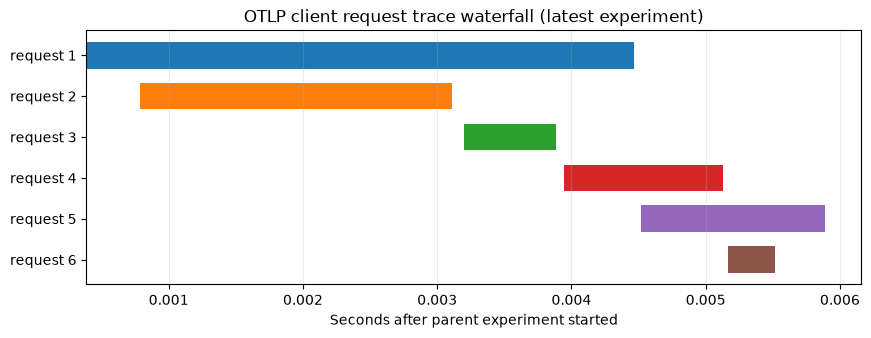

In [9]:
from pathlib import Path
import json

def read_otlp_jsonl(path):
    if not Path(path).exists():
        return []
    objects = []
    for line in Path(path).read_text(encoding='utf-8').splitlines():
        if line.strip():
            try:
                objects.append(json.loads(line))
            except json.JSONDecodeError:
                print('Skipped one incomplete JSON line (try again after export finishes).')
    return objects

def otlp_value(val):
    if not isinstance(val, dict):
        return val
    for key in ['stringValue', 'intValue', 'doubleValue', 'boolValue']:
        if key in val:
            return val[key]
    return None

def attribute_map(attrs):
    return {a.get('key'): otlp_value(a.get('value', {})) for a in (attrs or [])}

all_spans = []
for envelope in read_otlp_jsonl(TRACE_FILE):
    for resource_spans in envelope.get('resourceSpans', []):
        resource_attrs = attribute_map(resource_spans.get('resource', {}).get('attributes', []))
        for scope in resource_spans.get('scopeSpans', []):
            for span in scope.get('spans', []):
                attrs = attribute_map(span.get('attributes', []))
                all_spans.append({
                    'trace_id': span.get('traceId'), 'span_id': span.get('spanId'),
                    'parent_span_id': span.get('parentSpanId', ''),
                    'name': span.get('name'),
                    'service': resource_attrs.get('service.name'),
                    'start_ns': int(span.get('startTimeUnixNano', 0)),
                    'end_ns': int(span.get('endTimeUnixNano', 0)),
                    'e2e_s': attrs.get('lab.e2e_s'),
                    'ttft_ms': attrs.get('lab.ttft_ms'),
                    'output_tokens': attrs.get('lab.output_tokens'),
                })

traces_df = pd.DataFrame(all_spans)
if traces_df.empty:
    print('No OTLP spans read. Did you start the new Collector and run the previous sections?')
else:
    experiments = traces_df[traces_df.name == 'vllm.benchmark.otlp_experiment']
    if experiments.empty:
        print('No benchmark experiment parent span found yet. Wire demo traces:', len(traces_df))
    else:
        latest = experiments.sort_values('start_ns').iloc[-1]
        chosen = traces_df[traces_df.trace_id == latest.trace_id].copy()
        chosen['offset_s'] = (chosen.start_ns - latest.start_ns) / 1e9
        chosen['duration_s'] = (chosen.end_ns - chosen.start_ns) / 1e9
        display(chosen[['name', 'span_id', 'parent_span_id',
                        'offset_s', 'duration_s', 'ttft_ms', 'output_tokens']]
                .sort_values('offset_s').round(3))
        child = chosen[chosen.name == 'vllm.client.request'].sort_values('offset_s')
        if not child.empty:
            fig, ax = plt.subplots(figsize=(10, max(3.0, len(child)*0.55)))
            for i, (_, r) in enumerate(child.iterrows()):
                ax.barh(i, r['duration_s'], left=r['offset_s'], height=0.65)
            ax.set_yticks(range(len(child)))
            ax.set_yticklabels([f'request {i+1}' for i in range(len(child))])
            ax.invert_yaxis()
            ax.set_xlabel('Seconds after parent experiment started')
            ax.set_title('OTLP client request trace waterfall (latest experiment)')
            ax.grid(axis='x', alpha=0.25)
            plt.show()

### Inspect **pushed** OTLP metrics

Here we look in the second output file for `lab.client.requests.completed`, `lab.client.e2e_latency`, and `lab.client.ttft`. These are **SDK-created client metrics**, not vLLM's Prometheus counters. The Collector exported them into a local file. A file is not a queryable metrics database; in production the Collector would typically forward OTLP to an observability backend.

In [10]:
metric_names = []
metric_exports = read_otlp_jsonl(METRIC_FILE)
for envelope in metric_exports:
    for resource_metric in envelope.get('resourceMetrics', []):
        for scope_metric in resource_metric.get('scopeMetrics', []):
            for m in scope_metric.get('metrics', []):
                metric_names.append(m.get('name'))
print('Number of OTLP metric export messages:', len(metric_exports))
print('Metric names observed:')
for name in sorted(set(x for x in metric_names if x)):
    print(' •', name)
if not metric_exports:
    print('No metric export file found yet; check the new Collector Terminal and retry.')

Number of OTLP metric export messages: 398
Metric names observed:
 • lab.client.e2e_latency
 • lab.client.requests.completed
 • lab.client.ttft


## 21 — Compare the two transports and clean up **only our lab processes**

**Compare, don't confuse:**

| Aspect | Existing Prometheus scrape | New OTLP push |
|---|---|---|
| Source | vLLM's server metrics (`/metrics`) | Instrumented Jupyter benchmark client |
| Transport | Collector scrapes Prometheus text; Prometheus scrapes Collector's :8889 | Client SDK POSTs OTLP/HTTP to Collector :14318 |
| Collected information | Running/waiting requests, KV cache, cumulative tokens, aggregate latencies | Per-request client trace IDs, parent/child spans, measured TTFT/E2E, custom client metric histograms |
| Destination | Prometheus time-series database | Local JSONL files (easy to inspect; **not** a production trace backend) |
| How to view | PromQL / charts | Flatten JSONL and plot trace waterfall |

**Practical production pattern:** vLLM server metrics can remain Prometheus-scraped while API gateways or agent services emit OTLP spans that show where an entire distributed request spends its time. A common Collector can receive **both**. OTLP isn't needed just to read vLLM's existing `/metrics`.

**Clean shutdown:** First run the provider shutdown cell below so all queued telemetry gets exported. Stop the **new OTLP Collector** with **Control+C in its own Terminal**. Leave the existing Collector, Prometheus, and vLLM alone unless you separately intend to stop those processes. The new files stay in `~/Pranav-vLLM-Lab/bench_results/` outside iCloud Drive.

In [ ]:
# # Run ONCE when finished sending OTLP telemetry (not before another OTLP run).
# if not globals().get('OTLP_PROVIDERS_STOPPED', False):
#     if 'trace_provider' in globals():
#         trace_provider.force_flush(timeout_millis=10000)
#         trace_provider.shutdown()
#     if 'meter_provider' in globals():
#         meter_provider.force_flush(timeout_millis=10000)
#         meter_provider.shutdown()
#     OTLP_PROVIDERS_STOPPED = True
#     print('OTLP SDK providers shut down. You can stop only the separate OTLP Collector Terminal now.')
# else:
#     print('OTLP SDK providers already stopped. To run again, rerun the setup section first.')

In [11]:

# Verify request-level measurements
print("Individual request measurements:")
display(
    OTLP_DF[
        ["request_id", "status", "e2e_s", "ttft_ms", "output_tokens"]
    ].sort_values("request_id")
)

print("\nSuccessful requests:",
      (OTLP_DF["status"] == "OK").sum(),
      "/", len(OTLP_DF))

print("\nTrace file exists:", TRACE_FILE.exists())
print("Metrics file exists:", METRIC_FILE.exists())

if TRACE_FILE.exists():
    print("Trace file size:", TRACE_FILE.stat().st_size, "bytes")

if METRIC_FILE.exists():
    print("Metrics file size:", METRIC_FILE.stat().st_size, "bytes")


Individual request measurements:


NameError: name 'OTLP_DF' is not defined